In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score

In [2]:
#1. IMPORT DATASET
df = pd.read_csv("house_rent.csv")

print("\n=====DATASET INFORMATION=====")
print(df.head())
print("\nDataset Shape:",df.shape)
print("\nColumn Names:",df.columns.tolist())
print("\nDataset Information:")
df.info()

#INTERPRETATION

print("\nINTERPRETATION:")
print("The dataset contains",df.shape[0],"house rental records.")
print("Each record represents a house with different rental attributes.")
print("The target variable for prediction is Rent.")


=====DATASET INFORMATION=====
    Posted On  BHK   Rent  Size            Floor    Area Type  \
0  2022-05-18    2  10000  1100  Ground out of 2   Super Area   
1  2022-05-13    2  20000   800       1 out of 3   Super Area   
2  2022-05-16    2  17000  1000       1 out of 3   Super Area   
3  2022-07-04    2  10000   800       1 out of 2   Super Area   
4  2022-05-09    2   7500   850       1 out of 2  Carpet Area   

              Area Locality     City Furnishing Status  Tenant Preferred  \
0                    Bandel  Kolkata       Unfurnished  Bachelors/Family   
1  Phool Bagan, Kankurgachi  Kolkata    Semi-Furnished  Bachelors/Family   
2   Salt Lake City Sector 2  Kolkata    Semi-Furnished  Bachelors/Family   
3               Dumdum Park  Kolkata       Unfurnished  Bachelors/Family   
4             South Dum Dum  Kolkata       Unfurnished         Bachelors   

   Bathroom Point of Contact  
0         2    Contact Owner  
1         1    Contact Owner  
2         1    Contact Owner

In [3]:
#2.DATA QUALITY ANALYSIS

print("\n====DATA QUALITY ANALYSIS=====")

print("\nMissing Values:")
print(df.isnull().sum())


print("\nDuplicate Records:",df.duplicated().sum())

#INTERPRETATION

missing = df.isnull().sum().sum()
duplicates=df.duplicated().sum()

print("\nINTERPRETATION:")

if missing==0:
    print("There are no missing values in the dataset.")
else:
    print("The dataset contains",missing,"missing values")

if duplicates==0:
    print("There are no duplicate records.")
else:
    print("Duplicate records are present and should be investigated")


====DATA QUALITY ANALYSIS=====

Missing Values:
Posted On            0
BHK                  0
Rent                 0
Size                 0
Floor                0
Area Type            0
Area Locality        0
City                 0
Furnishing Status    0
Tenant Preferred     0
Bathroom             0
Point of Contact     0
dtype: int64

Duplicate Records: 0

INTERPRETATION:
There are no missing values in the dataset.
There are no duplicate records.


In [4]:
#.3 DESCRIPTIVE STATISTICS

print("\n====DESCRIPTIVE STATISTICS====")

print(df[['BHK',  'Size',  'Bathroom', 'Rent']].describe())

print("\nAverage Rent:",round(df["Rent"].mean(),2))

print("\nMedian Rent:",round(df["Rent"].median(),2))

print("\nMinimum Rent:",df["Rent"].min())
print("\nMaximum Rent:",df["Rent"].max())

#INTERPRETATION 
print("\nINTERPRETATION:")
print("The average monthly rent is Rs.",round(df["Rent"].mean(),2))

print("The median monthly rent is Rs.",round(df["Rent"].median(),2))

print("The minimum monthly rent is Rs.",df["Rent"].min())
print("The minimum monthly rent is Rs.",df["Rent"].max())

if df["Rent"].mean()>df["Rent"].median():
    print("Mean is less than median,indicating a possible lef-skewed rent distribution.")

else:
    print("Mean and median are approximately equal.")



====DESCRIPTIVE STATISTICS====
               BHK         Size     Bathroom          Rent
count  4746.000000  4746.000000  4746.000000  4.746000e+03
mean      2.083860   967.490729     1.965866  3.499345e+04
std       0.832256   634.202328     0.884532  7.810641e+04
min       1.000000    10.000000     1.000000  1.200000e+03
25%       2.000000   550.000000     1.000000  1.000000e+04
50%       2.000000   850.000000     2.000000  1.600000e+04
75%       3.000000  1200.000000     2.000000  3.300000e+04
max       6.000000  8000.000000    10.000000  3.500000e+06

Average Rent: 34993.45

Median Rent: 16000.0

Minimum Rent: 1200

Maximum Rent: 3500000

INTERPRETATION:
The average monthly rent is Rs. 34993.45
The median monthly rent is Rs. 16000.0
The minimum monthly rent is Rs. 1200
The minimum monthly rent is Rs. 3500000
Mean is less than median,indicating a possible lef-skewed rent distribution.


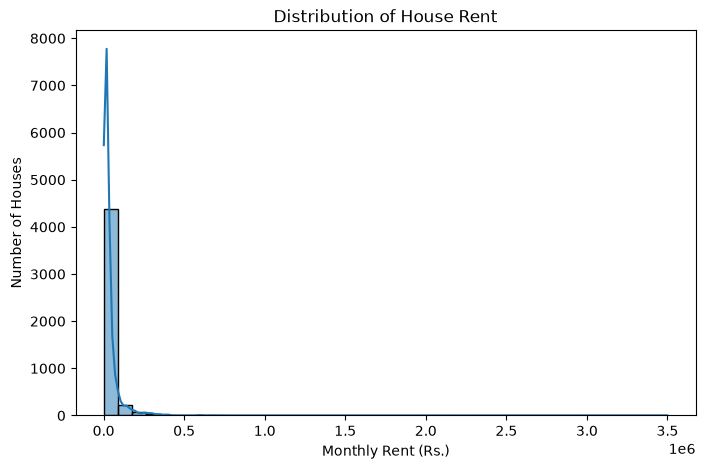


INTERPRETATION:
The histogram shows the frequency distribution of house event.
It helos identify the common rent ranges and unusually high or low values.


In [5]:
#4.HOUSE RENT DISTRIBUTION

plt.figure(figsize=(8,5))
sns.histplot(df["Rent"],bins=40,kde=True)

plt.title("Distribution of House Rent")
plt.xlabel("Monthly Rent (Rs.)")
plt.ylabel("Number of Houses")
plt.show()

print("\nINTERPRETATION:")

print("The histogram shows the frequency distribution of house event.")
print("It helos identify the common rent ranges and unusually high or low values.")




====BHK-WISE RENT ANALYSIS====
BHK
1     14139.22
2     22113.86
3     55863.06
4    168864.56
5    297500.00
6     73125.00
Name: Rent, dtype: float64


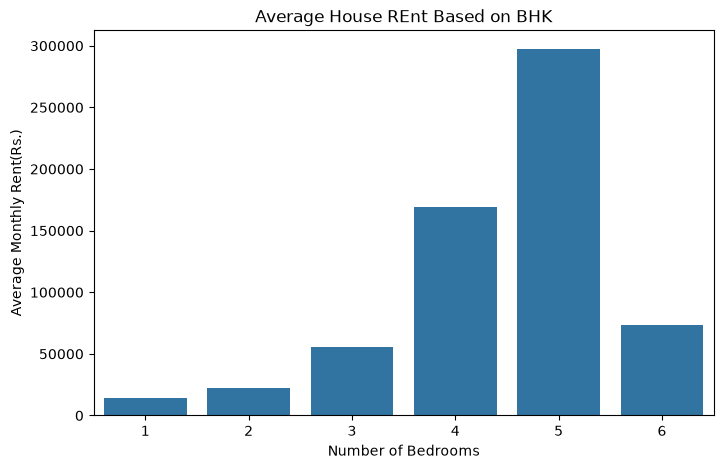


INTERPRETATION:
The highest average rent is for 5 BHK houses.
The lowest average rent is for 1 BHK houses.
Average rent does not increase consistently with BHK.


In [6]:
#5.BHK-WISE RENT ANALYSIS

print("\n====BHK-WISE RENT ANALYSIS====")
bhk_rent=df.groupby("BHK")["Rent"].mean().sort_index()
print(bhk_rent.round(2))

plt.figure(figsize=(8,5))
sns.barplot(data=df,x="BHK",y="Rent",errorbar=None)
plt.title("Average House REnt Based on BHK")
plt.xlabel("Number of Bedrooms")
plt.ylabel("Average Monthly Rent(Rs.)")

plt.show()

print("\nINTERPRETATION:")

highest_bhk= bhk_rent.idxmax()
lowest_bhk = bhk_rent.idxmin()

print("The highest average rent is for",highest_bhk,"BHK houses.")
print("The lowest average rent is for",lowest_bhk,"BHK houses.")


if bhk_rent.is_monotonic_increasing:
    print("Average rent increases as the number of bedrooms increases.")

else:
    print("Average rent does not increase consistently with BHK.")
    


====CITY-WISE RENT ANALYSIS====
City
Mumbai       85321.20
Delhi        29461.98
Bangalore    24966.37
Chennai      21614.09
Hyderabad    20555.05
Kolkata      11645.17
Name: Rent, dtype: float64


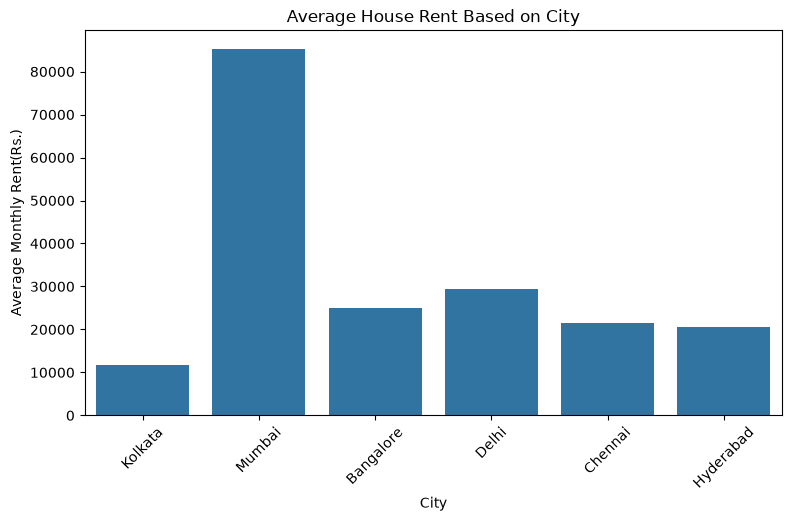


INTERPRETATION:
The city with the highest average rent is  Mumbai
The city with the lowest average rent is  Kolkata
Rental prices vary across cities due to differences in location and demand.


In [7]:
#6.CITY-WISE RENT ANALYSIS

city_rent = df.groupby("City")["Rent"].mean().sort_values(ascending=False)


print("\n====CITY-WISE RENT ANALYSIS====")

print(city_rent.round(2))

plt.figure(figsize=(9,5))
sns.barplot(data=df,x="City",y="Rent",errorbar=None)
plt.title("Average House Rent Based on City")
plt.xlabel("City")
plt.ylabel("Average Monthly Rent(Rs.)")
plt.xticks(rotation=45)

plt.show()

print("\nINTERPRETATION:")



print("The city with the highest average rent is ",city_rent.idxmax())
print("The city with the lowest average rent is ",city_rent.idxmin())


print("Rental prices vary across cities due to differences in location and demand.")


====FURNISHING-WISE AVERAGE RENT====
Furnishing Status
Furnished         56110.31
Semi-Furnished    38718.81
Unfurnished       22461.64
Name: Rent, dtype: float64


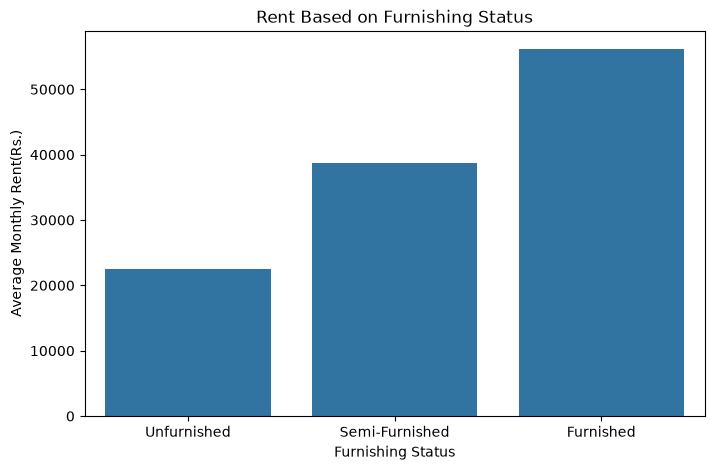


INTERPRETATION:
The highest average rent is for Furnished
The lowest average rent is for Unfurnished
Furnishing status is associated with differences in rental prices.


In [8]:
#7. FURNISHING STATUS ANALYSIS

furnish_rent = df.groupby("Furnishing Status")["Rent"].mean().sort_values(ascending=False)


print("\n====FURNISHING-WISE AVERAGE RENT====")

print(furnish_rent.round(2))

plt.figure(figsize=(8,5))
sns.barplot(data=df,x="Furnishing Status",y="Rent",errorbar=None)
plt.title("Rent Based on Furnishing Status")
plt.xlabel("Furnishing Status")
plt.ylabel("Average Monthly Rent(Rs.)")


plt.show()

print("\nINTERPRETATION:")



print("The highest average rent is for",furnish_rent.idxmax())
print("The lowest average rent is for",furnish_rent.idxmin())


print("Furnishing status is associated with differences in rental prices.")



=====CORRELATION MATRIX=====


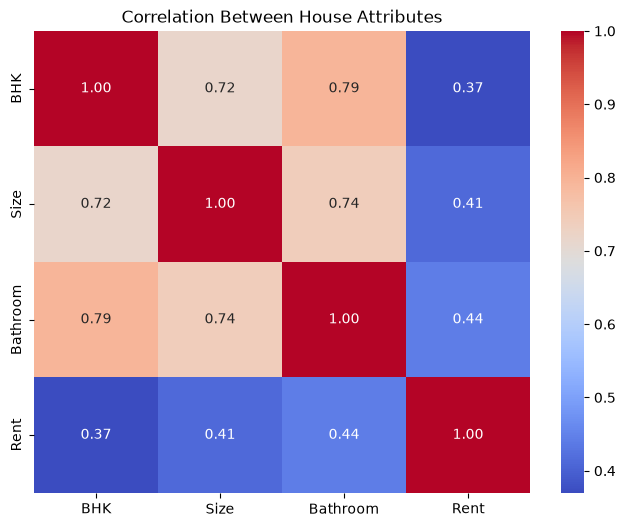


INTERPRETATION:
Attribute having the highest positive correlation with rent =: Bathroom
Attribute having the lowest correlation with rent: BHK
Positive correlation indicates that two variables tend to increase together.
Negtive correleation indicates an inverse relationsip.
Correlation does not necessarily imply causation.


In [9]:
#8. CORRELATION ANALYSIS

numeric_data = df[["BHK","Size","Bathroom","Rent"]]

correlation = numeric_data.corr()

print("\n=====CORRELATION MATRIX=====")
plt.figure(figsize=(8,6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between House Attributes")
plt.show()

print("\nINTERPRETATION:")

rent_corr = correlation["Rent"].drop("Rent").sort_values(ascending=False)

print("Attribute having the highest positive correlation with rent =:",rent_corr.idxmax())

print("Attribute having the lowest correlation with rent:", rent_corr.idxmin())

print("Positive correlation indicates that two variables tend to increase together.")
print("Negtive correleation indicates an inverse relationsip.")
print("Correlation does not necessarily imply causation.")

In [ ]:
# 9.PREPARE DATA FOR LINEAR REGRESSION

print("\n======LINEAR REGRESSION =======")

# select input attributes

features = [
    "BHK",
    "Size",
    "Floor",
    "Area Type",
    "Area Locality",
    "City",
    "Furnishing Status",
    "Tenant Preferred",
    "Bathroom"
]

x = df[features]
y = df["Rent"]
# Numerical attributes

num_cols = ["BHK", "Size", "Bathroom"]

# Categorical attributes

cat_cols = [
    "Floor",
    "Area Type",
    "Area Locality",
    "City",
    "Furnishing Status",
    "Tenant Preferred"
]

# Convert categorical data into numerical values

preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_cols),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                      ("encoder", OneHotEncoder(handle_unknown="ignore", min_frequency=5))]), cat_cols)
])


======LINEAR REGRESSION =======


In [12]:
#10.SPLIT DATASET

X_train,X_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

print("\nTraining Records:",len(X_train))

print("Testing Records:",len(X_test))

print("\nINTERPRETATION:")

print("80% of the records are used to train the model.")
print("20% of the records are used to test the model.")
print("Training data helps the model learn the relationship between")
print("house attributes and monthly rent.")





Training Records: 3796
Testing Records: 950

INTERPRETATION:
80% of the records are used to train the model.
20% of the records are used to test the model.
Training data helps the model learn the relationship between
house attributes and monthly rent.


In [13]:
#11. CREATE AND TRAIN MODEL

model = Pipeline([
    ("preprocessor",preprocessor),
    ("regression",LinearRegression())
])

model.fit(X_train,y_train)

print("Linear Regression Model Trained Successfully.")

Linear Regression Model Trained Successfully.


In [14]:
#12.PREDICT TEST DATA

y_pred = model.predict(X_test)

In [15]:
# ------------------------------------------------
# 13. MODEL EVALUATION
# ------------------------------------------------

mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))

r2 = r2_score(y_test, y_pred)

print("\n========== MODEL EVALUATION ==========")

print("Mean Absolute Error (MAE):", round(mae, 2))
print("Root Mean Squared Error (RMSE):", round(rmse, 2))
print("R2 Score:", round(r2, 3))

print("\nINTERPRETATION:")

print("MAE represents the average absolute prediction error.")
print("RMSE measures prediction error and gives more weight to large errors.")

if r2 >= 0:
    print("The model explains approximately", round(r2 * 100, 2),
          "% of the variation in house rent.")
else:
    print("The model performs worse than predicting the average test rent.")

if r2 >= 0.8:
    print("The model has a strong fit on the test dataset.")
elif r2 >= 0.5:
    print("The model has a moderate fit on the test dataset.")
else:
    print("The model has a relatively weak fit and may need improvement.")


========== MODEL EVALUATION ==========
Mean Absolute Error (MAE): 22766.72
Root Mean Squared Error (RMSE): 43971.02
R2 Score: 0.515

INTERPRETATION:
MAE represents the average absolute prediction error.
RMSE measures prediction error and gives more weight to large errors.
The model explains approximately 51.49 % of the variation in house rent.
The model has a moderate fit on the test dataset.



========== ACTUAL VS PREDICTED RENT ==========
   Actual Rent  Predicted Rent
0        16000        28135.33
1        12000        18776.49
2        28000        90889.77
3         8000        76226.57
4        46000        87159.83
5        17000        19816.38
6        57000        84223.60
7         9500        14392.50
8       400000       273644.07
9        15000         7023.78


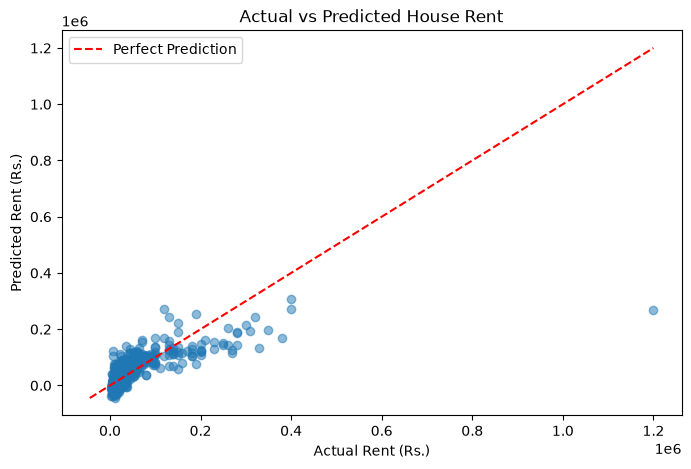


INTERPRETATION:
Points closer to the diagonal line indicate more accurate predictions.
Points farther from the line indicate larger prediction errors.


In [16]:
# ------------------------------------------------
# 14. ACTUAL VS PREDICTED RENT
# ------------------------------------------------

result = pd.DataFrame({
    "Actual Rent": y_test.values,
    "Predicted Rent": y_pred
})

print("\n========== ACTUAL VS PREDICTED RENT ==========")
print(result.head(10).round(2))

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.5)

plt.xlabel("Actual Rent (Rs.)")
plt.ylabel("Predicted Rent (Rs.)")
plt.title("Actual vs Predicted House Rent")

# Reference line
limits = [
    min(y_test.min(), y_pred.min()),
    max(y_test.max(), y_pred.max())
]

plt.plot(limits, limits, "r--", label="Perfect Prediction")
plt.legend()
plt.show()

print("\nINTERPRETATION:")
print("Points closer to the diagonal line indicate more accurate predictions.")
print("Points farther from the line indicate larger prediction errors.")

In [17]:
# ------------------------------------------------
# 15. PREDICT RENT FOR A NEW HOUSE
# ------------------------------------------------

new_house = pd.DataFrame([{
    "BHK": 2,
    "Size": 1000,
    "Floor": "1 out of 2",
    "Area Type": "Super Area",
    "Area Locality": "Electronic City",
    "City": "Bangalore",
    "Furnishing Status": "Semi-Furnished",
    "Tenant Preferred": "Bachelors/Family",
    "Bathroom": 2
}])

predicted_rent = model.predict(new_house)

print("\n========== HOUSE RENT PREDICTION ==========")

print("House Details:")
print(new_house.to_string(index=False))

print("\nPredicted Monthly Rent: Rs.",
      round(predicted_rent[0], 2))

print("\nINTERPRETATION:")
print("The trained Linear Regression model estimates the monthly rent")
print("based on the supplied house attributes.")
print("The predicted value is an estimate, not a guaranteed market rent.")


========== HOUSE RENT PREDICTION ==========
House Details:
 BHK  Size      Floor  Area Type   Area Locality      City Furnishing Status Tenant Preferred  Bathroom
   2  1000 1 out of 2 Super Area Electronic City Bangalore    Semi-Furnished Bachelors/Family         2

Predicted Monthly Rent: Rs. 26212.69

INTERPRETATION:
The trained Linear Regression model estimates the monthly rent
based on the supplied house attributes.
The predicted value is an estimate, not a guaranteed market rent.


In [18]:
# ------------------------------------------------
# 16. FINAL RESULT
# ------------------------------------------------

print("\n========== RESULT ==========")

print("Data analysis completed successfully.")
print("Linear Regression model trained and evaluated.")
print("House rent prediction completed successfully.")


========== RESULT ==========
Data analysis completed successfully.
Linear Regression model trained and evaluated.
House rent prediction completed successfully.
